<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/2-Ejercicios/04-Agrupamiento-kMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Agrupamiento k-Means
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Andrés Merino &bull; Periodo 2026-2
            </font></p>
        </td>  
    </tr>
</table>

---
## <font color='264CC7'> Introducción </font>

A lo largo de este taller, aplicaremos el algoritmo de agrupamiento k-Means al conjunto de datos seleccionado en las primeras semanas.

Los paquetes necesarios son:

In [52]:
# Paquetes necesarios
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt  # Visualización
import plotly.express as px # Para visualización interactiva

from sklearn.preprocessing import StandardScaler  # Estandarización de datos

from sklearn.datasets import make_blobs # Creación de datos de prueba
from sklearn.cluster import KMeans  # Algoritmo K-means
from sklearn.decomposition import PCA # Análisis de componentes principales


---
## <font color='264CC7'> Preprocesamiento de datos </font>

Usa el mismo conjunto de datos que seleccionaste en las primeras semanas y empleaste en el ejercicio de agrupamiento jerárquico. El conjunto Pokémon del notebook de clase es solo un ejemplo. En Colab, carga tu archivo desde una fuente accesible o súbelo a la sesión y documenta cómo repetir la carga.

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Carga el conjunto de datos y procésalos:
<ul>
  <li>Muestra algunos datos.</li>
  <li>Muestra una descripción de los datos.</li>
  <li>Trata los faltantes y escala las variables numéricas cuando sus escalas sean diferentes; excluye identificadores y etiquetas de la matriz de agrupamiento.</li>
</ul>
</div>

In [53]:
url = 'https://raw.githubusercontent.com/juanfercaicedo/AprendizajeAutomaticoInicial/refs/heads/main/Dataset/futbollStats.csv'
datos = pd.read_csv(url)

# 1. Mostrar algunos datos
display(datos.head())

# 2. Descripción general y valores faltantes
print("\nInformación y tipos de datos:")
print(datos.info())

print("\nEstadísticas descriptivas (numéricas):")
display(datos.describe().T)

# 3. Tratamiento de faltantes y selección de variables numéricas para k-Means
df_prep = datos.copy()

# Identificar columnas numéricas y excluir identificadores/etiquetas/metadatos de la imagen
cols_excluir = [
    'ranking_influencia',
    'jugador',
    'nacionalidad',
    'confederacion',
    'posicion_principal',
    'periodo_activo_siglo_xxi',
    'clubes_emblematicos'
]

posibles_excluir = [col for col in df_prep.columns if col in cols_excluir]
print("\nColumnas excluidas por ser identificadores/etiquetas:", posibles_excluir)

cols_numericas = [
    col for col in df_prep.select_dtypes(include=[np.number]).columns
    if col not in posibles_excluir
]

# Imputar valores faltantes en variables numéricas con la mediana
for col in cols_numericas:
    if df_prep[col].isnull().any():
        df_prep[col] = df_prep[col].fillna(df_prep[col].median())

# Eliminar filas que aún tengan nulos en las columnas de análisis (si ocurriera)
df_prep = df_prep.dropna(subset=cols_numericas).reset_index(drop=True)

# Estandarización (media = 0, desviación estándar = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_prep[cols_numericas])
X_scaled_df = pd.DataFrame(X_scaled, columns=cols_numericas)

print("\nVariables usadas para el agrupamiento:", cols_numericas)
print("Matriz estandarizada lista:", X_scaled.shape)

,ranking_influencia,jugador,nacionalidad,confederacion,posicion_principal,periodo_activo_siglo_xxi,clubes_emblematicos,partidos_jugados,minutos_jugados,goles,asistencias,contribuciones_gol_por_90,pases_exitosos,pases_intentados,precision_pases_pct,pases_clave,tarjetas_amarillas,tarjetas_rojas,titulos_colectivos,legado_e_influencia
0,1,Lionel Messi,Argentina,CONMEBOL,Delantero / Mediapunta,2004-2026,FC Barcelona / PSG / Inter Miami,1185,98028,937,428,1.25,61479,72413,84.9,2972,102,3,49,Máximo referente ofensivo del siglo XXI; redef...
1,2,Cristiano Ronaldo,Portugal,UEFA,Delantero / Extremo,2002-2026,Sporting CP / Man United / Real Madrid / Juven...,1343,113998,985,265,0.99,44615,55012,81.1,1801,134,11,37,Máximo goleador histórico del fútbol oficial y...
2,3,Zinedine Zidane,Francia,UEFA,Mediocentro Ofensivo,2000-2006,Juventus / Real Madrid,318,26661,64,78,0.48,19225,21971,87.5,774,46,7,15,Elegancia técnica y control del ritmo en grand...
3,4,Ronaldinho Gaúcho,Brasil,CONMEBOL,Extremo / Mediapunta,2000-2015,PSG / FC Barcelona / AC Milan / Atlético Mineiro,685,55116,268,189,0.75,30328,36806,82.4,1498,74,8,14,Revolucionó el desequilibrio individual y devo...
4,5,Andrés Iniesta,España,UEFA,Mediocentro,2002-2024,FC Barcelona / Vissel Kobe,965,75422,97,192,0.34,57022,63008,90.5,1607,68,0,39,Arquitecto del juego de posición y autor del g...



Información y tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 234 entries, 0 to 233
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ranking_influencia         234 non-null    int64  
 1   jugador                    234 non-null    object 
 2   nacionalidad               234 non-null    object 
 3   confederacion              234 non-null    object 
 4   posicion_principal         234 non-null    object 
 5   periodo_activo_siglo_xxi   234 non-null    object 
 6   clubes_emblematicos        234 non-null    object 
 7   partidos_jugados           234 non-null    int64  
 8   minutos_jugados            234 non-null    int64  
 9   goles                      234 non-null    int64  
 10  asistencias                234 non-null    int64  
 11  contribuciones_gol_por_90  234 non-null    float64
 12  pases_exitosos             234 non-null    int64  
 13  pases_intentados   

,count,mean,std,min,25%,50%,75%,max
ranking_influencia,234.0,117.500000,67.694165,1.0,59.25,117.50,175.75,234.00
partidos_jugados,234.0,638.884615,199.872383,164.0,512.00,645.00,765.00,1343.00
minutos_jugados,234.0,51572.175214,16813.560967,12852.0,39238.25,51845.00,61506.50,113998.00
goles,234.0,143.974359,151.891251,0.0,44.00,88.00,212.00,985.00
asistencias,234.0,94.688034,71.677096,1.0,42.00,78.00,135.50,428.00
contribuciones_gol_por_90,234.0,0.414274,0.276875,0.0,0.16,0.43,0.64,1.25
pases_exitosos,234.0,27282.863248,13433.183599,2935.0,17404.75,25257.50,34731.25,81360.00
pases_intentados,234.0,31953.192308,14637.036694,3832.0,21195.25,30545.50,40778.50,87484.00
precision_pases_pct,234.0,84.088034,4.663099,72.2,80.60,84.60,88.00,93.50
pases_clave,234.0,791.615385,521.518587,4.0,407.25,739.00,1074.25,2972.00



Columnas excluidas por ser identificadores/etiquetas: ['ranking_influencia', 'jugador', 'nacionalidad', 'confederacion', 'posicion_principal', 'periodo_activo_siglo_xxi', 'clubes_emblematicos']

Variables usadas para el agrupamiento: ['partidos_jugados', 'minutos_jugados', 'goles', 'asistencias', 'contribuciones_gol_por_90', 'pases_exitosos', 'pases_intentados', 'precision_pases_pct', 'pases_clave', 'tarjetas_amarillas', 'tarjetas_rojas', 'titulos_colectivos']
Matriz estandarizada lista: (234, 12)


---
## <font color='264CC7'> Determinación del número de clusters </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Propón un número de clústeres para k-Means utilizando el método del codo.
<ul>
  <li>Genera una gráfica de inercia para valores de k entre 1 y 10, sin superar el número de observaciones disponibles.</li>
  <li>Identifica si aparece un codo claro; si no aparece, explica cómo elegirías un valor razonable.</li>
  <li>Justifica tu elección y explica por qué la inercia, por sí sola, no determina la calidad de los grupos.</li>
</ul>
</div>


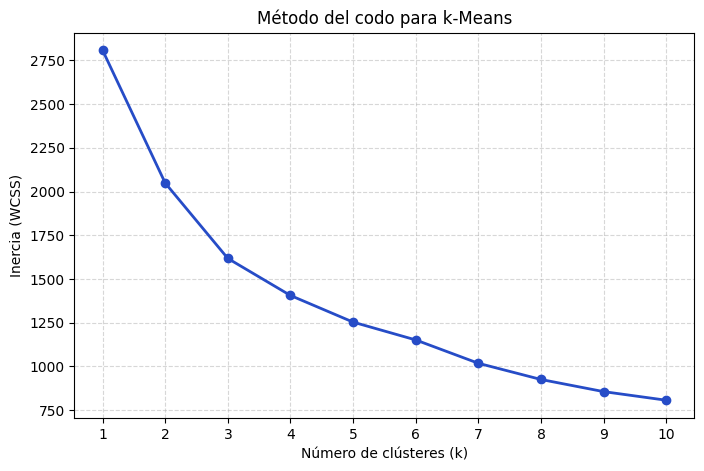

In [54]:
n_obs = X_scaled.shape[0]
k_max = min(10, n_obs)
rango_k = range(1, k_max + 1)

inercias = []
for k in rango_k:
    modelo = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    modelo.fit(X_scaled)
    inercias.append(modelo.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(rango_k), inercias, marker='o', linewidth=2, color='#264CC7')
plt.title('Método del codo para k-Means')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Inercia (WCSS)')
plt.xticks(list(rango_k))
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

---
## <font color='264CC7'> Asignación de grupos y análisis </font>


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza un análisis de los grupos obtenidos.
<ul>
  <li>Asigna los grupos.</li>
  <li>Revisa la media de cada grupo.</li>
  <li>Revisa el mínimo y máximo de cada grupo.</li>
  <li>Muestra algunos integrantes de cada grupo.</li>
</ul>
</div>

In [55]:
k_optimo = 4  # Ajusta este valor según tu análisis del método del codo

kmeans = KMeans(n_clusters=k_optimo, init='k-means++', n_init=10, random_state=42)
df_prep['Cluster'] = kmeans.fit_predict(X_scaled)

print("Cantidad de observaciones por clúster:")
print(df_prep['Cluster'].value_counts().sort_index())

# Media por clúster
print("\nMedia por clúster:")
display(df_prep.groupby('Cluster')[cols_numericas].mean().round(2))

# Mínimo y máximo por clúster
print("\nMínimo y máximo por clúster:")
display(df_prep.groupby('Cluster')[cols_numericas].agg(['min', 'max']).round(2))

# Ejemplos de integrantes de cada clúster
cols_mostrar = [c for c in (posibles_excluir + cols_numericas[:4] + ['Cluster']) if c in df_prep.columns]
cols_mostrar = list(dict.fromkeys(cols_mostrar))

for c in sorted(df_prep['Cluster'].unique()):
    print(f"\n--- Ejemplos del Clúster {c} ---")
    display(df_prep[df_prep['Cluster'] == c][cols_mostrar].head(5))

Cantidad de observaciones por clúster:
Cluster
0    23
1    78
2    67
3    66
Name: count, dtype: int64

Media por clúster:


,partidos_jugados,minutos_jugados,goles,asistencias,contribuciones_gol_por_90,pases_exitosos,pases_intentados,precision_pases_pct,pases_clave,tarjetas_amarillas,tarjetas_rojas,titulos_colectivos
Cluster,,,,,,,,,,,,
0,949.65,76852.78,328.61,227.61,0.64,45804.35,53406.87,84.83,1756.78,98.65,4.17,27.96
1,439.09,35650.64,74.05,47.13,0.36,15737.29,18742.31,82.89,400.38,40.00,1.36,11.36
2,708.10,55374.19,252.76,141.70,0.64,23844.60,29032.45,81.47,1095.60,69.22,2.82,13.64
3,696.44,57719.00,51.83,56.85,0.18,37963.53,43054.77,87.90,609.05,103.76,4.95,19.97



Mínimo y máximo por clúster:


partidos_jugados       minutos_jugados         goles      asistencias  \
                     min   max             min     max   min  max         min   
Cluster                                                                         
0                    765  1343           62092  113998    75  985         144   
1                    164   864           12852   76503     0  368           1   
2                    512   942           39845   73146    86  468          64   
3                    488  1072           38044   92674     0  146           2   

             contribuciones_gol_por_90        ... precision_pases_pct        \
         max                       min   max  ...                 min   max   
Cluster                                       ...                             
0        428                      0.28  1.25  ...                77.4  93.5   
1        128                      0.00  1.12  ...                72.2  91.9   
2        248                      0.39  1.09  ...                75.3  89.1   
3        128                      0.00  0.43  ...                76.2  93.0   

        pases_clave       tarjetas_amarillas      tarjetas_rojas      \
                min   max                min  max            min max   
Cluster                                                                
0              1172  2972                 28  212              0  15   
1                 4  1028                 12   98              0   7   
2               555  1778                 24  138              0   9   
3                20  1201                 24  272              0  29   

        titulos_colectivos      
                       min max  
Cluster                         
0                       10  49  
1                        0  28  
2                        0  30  
3                        4  36  

[4 rows x 24 columns]


--- Ejemplos del Clúster 0 ---


,ranking_influencia,jugador,nacionalidad,confederacion,posicion_principal,periodo_activo_siglo_xxi,clubes_emblematicos,partidos_jugados,minutos_jugados,goles,asistencias,Cluster
0,1,Lionel Messi,Argentina,CONMEBOL,Delantero / Mediapunta,2004-2026,FC Barcelona / PSG / Inter Miami,1185,98028,937,428,0
1,2,Cristiano Ronaldo,Portugal,UEFA,Delantero / Extremo,2002-2026,Sporting CP / Man United / Real Madrid / Juven...,1343,113998,985,265,0
4,5,Andrés Iniesta,España,UEFA,Mediocentro,2002-2024,FC Barcelona / Vissel Kobe,965,75422,97,192,0
5,6,Xavi Hernández,España,UEFA,Mediocentro,2000-2019,FC Barcelona / Al-Sadd,1042,84729,118,236,0
6,7,Luka Modrić,Croacia,UEFA,Mediocentro,2003-2026,Dinamo Zagreb / Tottenham / Real Madrid,1085,86350,134,182,0


... (2 outputs left out)


--- Ejemplos del Clúster 2 ---


,ranking_influencia,jugador,nacionalidad,confederacion,posicion_principal,periodo_activo_siglo_xxi,clubes_emblematicos,partidos_jugados,minutos_jugados,goles,asistencias,Cluster
3,4,Ronaldinho Gaúcho,Brasil,CONMEBOL,Extremo / Mediapunta,2000-2015,PSG / FC Barcelona / AC Milan / Atlético Mineiro,685,55116,268,189,2
7,8,Thierry Henry,Francia,UEFA,Delantero,2000-2014,Arsenal / FC Barcelona / NY Red Bulls,768,62409,366,207,2
9,10,Kaká,Brasil,CONMEBOL,Mediocentro Ofensivo,2001-2017,São Paulo / AC Milan / Real Madrid / Orlando City,746,58388,237,168,2
19,20,Kylian Mbappé,Francia,UEFA,Delantero / Extremo,2015-2026,AS Mónaco / PSG / Real Madrid,615,49680,428,174,2
22,23,Vinícius Júnior,Brasil,CONMEBOL,Extremo,2017-2026,Flamengo / Real Madrid,512,39845,164,132,2



--- Ejemplos del Clúster 3 ---


,ranking_influencia,jugador,nacionalidad,confederacion,posicion_principal,periodo_activo_siglo_xxi,clubes_emblematicos,partidos_jugados,minutos_jugados,goles,asistencias,Cluster
12,13,Manuel Neuer,Alemania,UEFA,Portero,2005-2026,Schalke 04 / Bayern Múnich,942,84592,0,9,3
13,14,Sergio Ramos,España,UEFA,Defensa Central,2004-2026,Sevilla / Real Madrid / PSG / Monterrey,1072,91915,146,44,3
18,19,Gianluigi Buffon,Italia,UEFA,Portero,2000-2023,Parma / Juventus / PSG,986,88399,0,2,3
21,22,Rodri Hernández,España,UEFA,Pivote,2015-2026,Villarreal / Atlético Madrid / Manchester City,585,48785,46,54,3
25,26,Sergio Busquets,España,UEFA,Pivote,2008-2026,FC Barcelona / Inter Miami,955,77480,21,64,3


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Da una descripción de los grupos obtenidos. Asigna un nombre a cada grupo.
</div>

---
## <font color='264CC7'> Visualizaciones  </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza una visualización de los grupos obtenidos en 2D seleccionando dos variables que creas relevantes.
<ul>
  <li>¿Qué tan buenos te parecen los grupos?</li>
</ul>
</div>

In [56]:
var_x = cols_numericas[0]
var_y = cols_numericas[1] if len(cols_numericas) > 1 else cols_numericas[0]

fig = px.scatter(
    df_prep,
    x=var_x,
    y=var_y,
    color=df_prep['Cluster'].astype(str),
    hover_data=posibles_excluir if posibles_excluir else None,
    title=f'Clústeres k-Means en 2D: {var_x} vs {var_y}',
    labels={'color': 'Clúster'}
)
fig.show()

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Visualiza los grupos en dos componentes mediante PCA, usando la misma matriz preparada para el agrupamiento.
<ul>
  <li>Indica el porcentaje de varianza explicada por los dos componentes y comenta qué información puede perderse en la proyección.</li>
  <li>Evalúa la calidad de los grupos en la matriz preparada, no en la proyección 2D.</li>
</ul>
</div>

In [57]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

var_exp = pca.explained_variance_ratio_
print(f"Varianza explicada por PC1: {var_exp[0]*100:.2f}%")
print(f"Varianza explicada por PC2: {var_exp[1]*100:.2f}%")
print(f"Varianza total explicada (PC1 + PC2): {var_exp.sum()*100:.2f}%")

df_pca = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'Cluster': df_prep['Cluster'].astype(str),
    'jugador': df_prep['jugador']  # Añadimos la columna para el hover
})

fig_pca = px.scatter(
    df_pca,
    x='PC1',
    y='PC2',
    color='Cluster',
    hover_data=['jugador'],
    title='Visualización de clústeres k-Means mediante PCA (2 componentes)'
)
fig_pca.show()

Varianza explicada por PC1: 44.75%
Varianza explicada por PC2: 26.30%
Varianza total explicada (PC1 + PC2): 71.05%


---
## <font color='264CC7'> Métricas  </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Calcula la silueta de los grupos en la matriz preparada, siempre que haya entre 2 y n-1 grupos para n observaciones. Contrasta su valor con el tamaño y la interpretación de los grupos; compáralo con la partición jerárquica si usaste la misma matriz.
</div>

In [58]:
from sklearn.metrics import silhouette_score, silhouette_samples

n_clusters_actuales = df_prep['Cluster'].nunique()
if 2 <= n_clusters_actuales <= (X_scaled.shape[0] - 1):
    sil_promedio = silhouette_score(X_scaled, df_prep['Cluster'])
    print(f"Coeficiente de silueta promedio (k={n_clusters_actuales}): {sil_promedio:.4f}")

    df_prep['Silueta'] = silhouette_samples(X_scaled, df_prep['Cluster'])
    print("\nSilueta promedio por clúster:")
    print(df_prep.groupby('Cluster')['Silueta'].mean().round(4))
else:
    print("No es posible calcular la silueta: se requieren entre 2 y n-1 clústeres.")

Coeficiente de silueta promedio (k=4): 0.2456

Silueta promedio por clúster:
Cluster
0    0.0300
1    0.2525
2    0.3252
3    0.2317
Name: Silueta, dtype: float64
